# Exploring the fish-introduction dataset with distractors

This notebook **loads saved CSV files**. It never generates data, trains models,
changes labels/splits, or writes analysis files. Run cells in order.

The dataset contains 500 matched blocks of 10 children: four documented R=1,
four documented R=0, and two without documented introduction. FA is sampled
independently with probability 0.90 for R=1 and 0.05 for R=0. This is a controlled
synthetic mechanism experiment, not a clinical prevalence estimate.

Fever, Cough, Rash, SleepDisturbance, and DoctorVisit are irrelevant synthetic
distractors. Each has an independent Poisson(6) event count per child and
uniform timestamps over follow-up, using a separate random stream.

On creation, all saved-data checks passed, including preservation of the original
observations, FA labels, and split. The two dataset-focused tests also passed.
The cells below have deliberately **not been executed**.


## A. Dataset overview

The loader works when Jupyter starts in the repository or this dataset folder.
`patients_and_split.csv` contains ground-truth and inspection metadata; it is
not an extra collection of model input features. The observation table contains
one fixed Birth Date anchor and eight binary event features.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

folder_name = "fish_intro_dataset_distractors"
DATA_DIR = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates = [parent, parent / "data" / folder_name]
    for candidate in candidates:
        if candidate.name == folder_name and (candidate / "observations.csv").is_file():
            DATA_DIR = candidate
            break
    if DATA_DIR is not None:
        break
if DATA_DIR is None:
    raise FileNotFoundError("Open this notebook from the repository or dataset folder.")

BIRTH = "Birth Date Anchor"
FISH = "FishIntroduction"
SYMPTOMS = ["GI", "Vomiting"]
DISTRACTORS = ["Fever", "Cough", "Rash", "SleepDisturbance", "DoctorVisit"]
EVENT_FEATURES = [FISH, *SYMPTOMS, *DISTRACTORS]

observations = pd.read_csv(DATA_DIR / "observations.csv", parse_dates=["time"])
patients = pd.read_csv(
    DATA_DIR / "patients_and_split.csv",
    parse_dates=["birth", "followup_end", "a", "b", "signal_time", "fish_time"],
    dtype={"documented": bool},
)
validation = json.loads((DATA_DIR / "validation.json").read_text())
assert patients.patient_id.is_unique
assert set(observations.patient_id) == set(patients.patient_id)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Loaded:", DATA_DIR)


Loaded: /mnt/drive1/home/noreena/TemporalDecisionTree_clean/data/fish_intro_dataset_distractors


In [2]:
overview = pd.Series({
    "Children": len(patients),
    "Matched blocks": patients.block.nunique(),
    "Observations (including Birth anchors)": len(observations),
    "Features (including Birth anchor)": observations.feature_name.nunique(),
    "Binary event features": len(EVENT_FEATURES),
    "FA cases": int(patients.FA.sum()),
})
display(overview.to_frame("value"))
display(patients.groupby("partition").agg(
    children=("patient_id", "size"), blocks=("block", "nunique"),
    documented=("documented", "sum"), R_positive=("R", "sum"),
    FA_cases=("FA", "sum"), FA_prevalence=("FA", "mean"),
))
assert patients.groupby("block").partition.nunique().eq(1).all()
display(observations.head(12))
display(patients.head(10))
print("Saved generator validation:")
display(validation)


,value
Children,5000
Matched blocks,500
Observations (including Birth anchors),185513
Features (including Birth anchor),9
Binary event features,8
FA cases,1940


,children,blocks,documented,R_positive,FA_cases,FA_prevalence
partition,,,,,,
test,1000,100,800,400,389,0.38900
train,4000,400,3200,1600,1551,0.38775


,patient_id,time,feature_name,value
0,F000_01,2012-06-27 00:00:00,Birth Date Anchor,2012-06-27 00:00:00
1,F000_01,2013-09-05 20:44:04,Cough,1
2,F000_01,2013-10-16 23:43:29,Cough,1
3,F000_01,2013-12-23 01:58:19,Cough,1
4,F000_01,2014-05-28 03:38:20,Cough,1
5,F000_01,2014-11-30 22:30:47,Cough,1
6,F000_01,2012-07-30 18:48:48,DoctorVisit,1
7,F000_01,2013-04-22 04:31:10,DoctorVisit,1
8,F000_01,2013-08-19 19:41:15,DoctorVisit,1
9,F000_01,2013-12-09 06:27:18,DoctorVisit,1


,patient_id,block,profile,scenario,signal_type,partition,documented,birth,followup_end,a,b,signal_time,fish_time,R,fa_probability,FA
0,F000_01,0,1,ordinary,GI,train,True,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-03-21 13:48:29,2014-03-03 13:12:59,1,0.90,1
1,F000_02,0,2,ordinary,GI,train,True,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-03-21 13:48:29,2014-03-03 13:12:59,1,0.90,1
2,F000_03,0,3,ordinary,GI,train,True,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-05-31 18:59:25,2014-05-03 13:12:59,1,0.90,1
3,F000_04,0,4,ordinary,GI,train,True,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-05-31 18:59:25,2014-05-03 13:12:59,1,0.90,1
4,F000_05,0,5,ordinary,GI,train,True,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-05-31 18:59:25,2014-03-03 13:12:59,0,0.05,0
5,F000_06,0,6,ordinary,GI,train,True,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-05-31 18:59:25,2014-03-03 13:12:59,0,0.05,0
6,F000_07,0,7,ordinary,GI,train,True,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-03-21 13:48:29,2014-05-03 13:12:59,0,0.05,0
7,F000_08,0,8,ordinary,GI,train,True,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-03-21 13:48:29,2014-05-03 13:12:59,0,0.05,0
8,F000_09,0,9,ordinary,GI,train,False,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-03-21 13:48:29,NaT,0,0.05,0
9,F000_10,0,10,ordinary,GI,train,False,2012-06-27,2014-12-27,2014-03-03 13:12:59,2014-05-03 13:12:59,2014-05-31 18:59:25,NaT,0,0.05,0


Saved generator validation:


{'passed': True,
 'patients': 5000,
 'observations': 185513,
 'blocks': 500,
 'documented_R1': 2000,
 'documented_R0': 2000,
 'undocumented': 1000,
 'actual_FA_cases': 1940,
 'expected_FA_cases': 1950,
 'distractors': {'features': ['Fever',
   'Cough',
   'Rash',
   'SleepDisturbance',
   'DoctorVisit'],
  'poisson_mean': 6,
  'timestamp_distribution': 'uniform seconds over full follow-up',
  'seed_spawn_key': [3]},
 'checks': ['actual timestamp R before FA sampling',
  '4/4/2 in every block',
  'matched documented marginal event times and counts',
  'no simultaneous fish/symptom events',
  '30-month follow-up',
  'background GI and vomiting in every child',
  'intact split blocks']}

In [7]:
# observations[observations['patient_id'] == 'F000_01']
observations[observations['feature_name'] == 'GI']

,patient_id,time,feature_name,value
20,F000_01,2014-03-21 13:48:29,GI,1
21,F000_01,2014-09-05 07:53:42,GI,1
52,F000_02,2014-03-21 13:48:29,GI,1
53,F000_02,2014-09-05 07:53:42,GI,1
98,F000_03,2014-05-31 18:59:25,GI,1
...,...,...,...,...
185427,F499_08,2013-03-15 15:06:28,GI,1
185458,F499_09,2011-08-17 19:09:36,GI,1
185459,F499_09,2013-03-15 15:06:28,GI,1
185497,F499_10,2011-08-17 19:09:36,GI,1


## B. Feature exploration

All event rows have value 1. The absence of an event row means no documented
occurrence, not a recorded value of zero. Counts below explicitly include children
with zero events. Birth Date is shown in the feature summary but excluded from
event-count plots because it is a fixed anchor, not an event.


,observations,children_with_observations,children_without_observations,fraction_without_observations,mean_events_per_child
feature_name,,,,,
Birth Date Anchor,5000,5000,0,0.0000,1.0000
FishIntroduction,4000,4000,1000,0.2000,0.8000
GI,13120,5000,0,0.0000,2.6240
Vomiting,12790,5000,0,0.0000,2.5580
Fever,30127,4994,6,0.0012,6.0254
Cough,30309,4986,14,0.0028,6.0618
Rash,29685,4986,14,0.0028,5.9370
SleepDisturbance,30318,4987,13,0.0026,6.0636
DoctorVisit,30164,4995,5,0.0010,6.0328


,count,mean,std,min,25%,50%,75%,max
feature_name,,,,,,,,
FishIntroduction,5000.0,0.8000,0.400040,0.0,1.0,1.0,1.0,1.0
GI,5000.0,2.6240,0.970985,1.0,2.0,3.0,3.0,4.0
Vomiting,5000.0,2.5580,0.937450,1.0,2.0,3.0,3.0,4.0
Fever,5000.0,6.0254,2.414191,0.0,4.0,6.0,8.0,16.0
Cough,5000.0,6.0618,2.482985,0.0,4.0,6.0,8.0,16.0
Rash,5000.0,5.9370,2.435697,0.0,4.0,6.0,8.0,16.0
SleepDisturbance,5000.0,6.0636,2.499361,0.0,4.0,6.0,8.0,16.0
DoctorVisit,5000.0,6.0328,2.495229,0.0,4.0,6.0,8.0,16.0


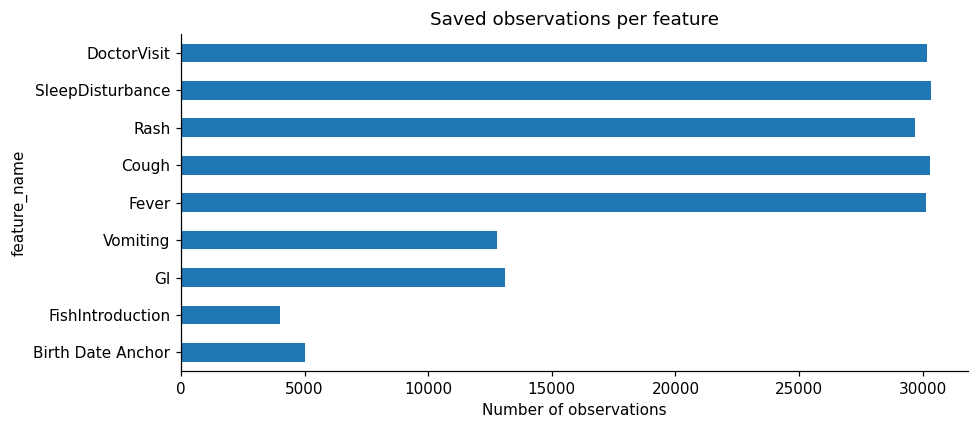

In [3]:
all_features = [BIRTH, *EVENT_FEATURES]
counts = (
    observations.groupby(["patient_id", "feature_name"]).size().unstack(fill_value=0)
    .reindex(index=patients.patient_id, columns=all_features, fill_value=0)
)
counts.index.name = "patient_id"
feature_summary = pd.DataFrame({
    "observations": counts.sum(),
    "children_with_observations": counts.gt(0).sum(),
    "children_without_observations": counts.eq(0).sum(),
    "fraction_without_observations": counts.eq(0).mean(),
    "mean_events_per_child": counts.mean(),
})
display(feature_summary)
display(counts[EVENT_FEATURES].describe().T)
feature_summary["observations"].plot.barh(figsize=(9, 4), xlabel="Number of observations")
plt.title("Saved observations per feature")
plt.tight_layout()
plt.show()


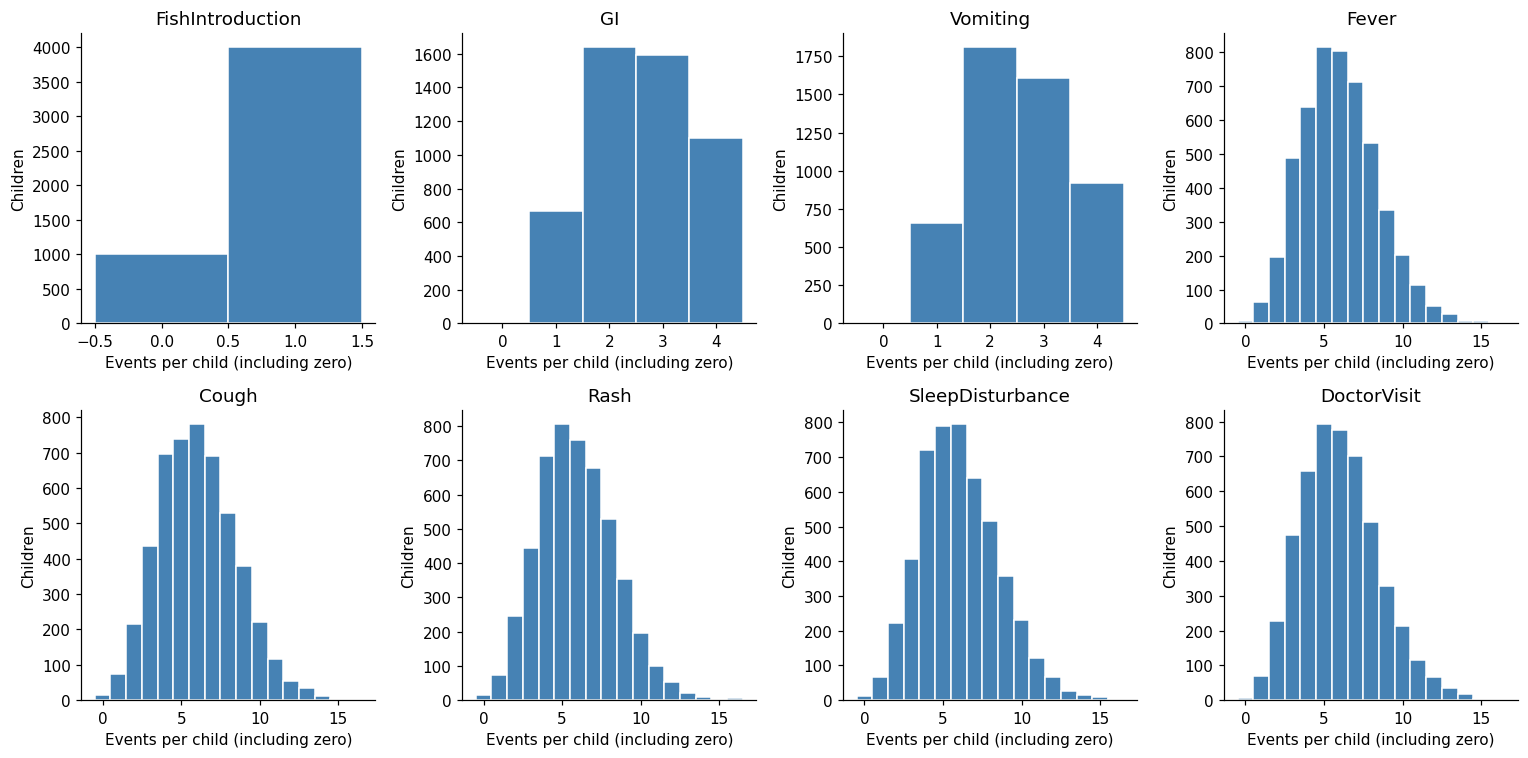

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, feature in zip(axes.flat, EVENT_FEATURES):
    values = counts[feature]
    bins = np.arange(-0.5, values.max() + 1.5, 1)
    ax.hist(values, bins=bins, color="steelblue", edgecolor="white")
    ax.set(title=feature, xlabel="Events per child (including zero)", ylabel="Children")
fig.tight_layout()
plt.show()


## C. Temporal exploration

For visualization, age is measured between successive **calendar-month birth
anniversaries**, with a linear fractional position within each month. This avoids
treating one month as 30 days. The actual rule in section D uses exact timestamps
and `pd.DateOffset(months=1)` relative to fish introduction.

Fish dates may extend past age 22 months because the later matched introduction
can be two months after the earlier one. Follow-up remains 30 calendar months.
Distractors have no special placement around introduction dates.


,Fish introduction age (calendar months)
count,4000.000000
mean,12.208603
std,6.403871
min,0.489019
25%,6.770072
50%,11.956548
75%,17.829120
max,23.999953


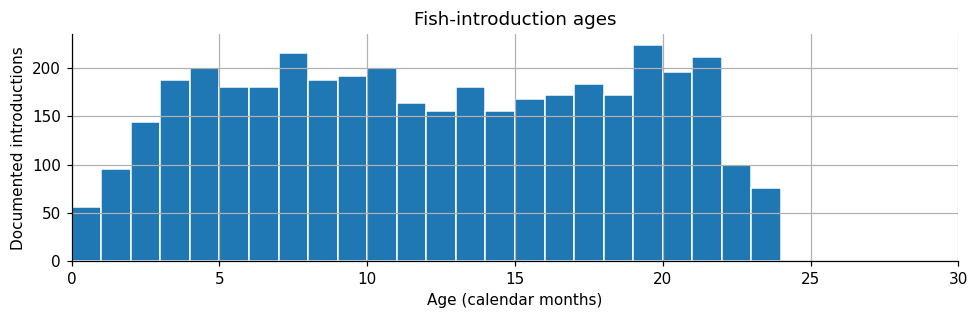

In [5]:
events = observations.loc[observations.feature_name.ne(BIRTH)].copy()
events["value"] = pd.to_numeric(events.value)
assert events.value.eq(1).all()
events = events.merge(
    patients[["patient_id", "birth", "followup_end"]],
    on="patient_id", validate="many_to_one",
)
assert events.time.between(events.birth, events.followup_end).all()

def add_calendar_age(frame):
    """Add a plotting coordinate; leave event timestamps unchanged."""
    result = frame.copy()
    result["age_months"] = np.nan
    for birth, indices in result.groupby("birth").groups.items():
        edges = pd.DatetimeIndex([
            birth + pd.DateOffset(months=m) for m in range(32)
        ]).to_numpy()
        times = result.loc[indices, "time"].to_numpy()
        month = np.searchsorted(edges, times, side="right") - 1
        fraction = (times - edges[month]) / (edges[month + 1] - edges[month])
        result.loc[indices, "age_months"] = month + fraction
    return result

events = add_calendar_age(events)
fish_events = events.loc[events.feature_name.eq(FISH)]
display(fish_events.age_months.describe().to_frame("Fish introduction age (calendar months)"))
fish_events.age_months.hist(bins=np.arange(0, 31), figsize=(9, 3), edgecolor="white")
plt.xlabel("Age (calendar months)")
plt.ylabel("Documented introductions")
plt.title("Fish-introduction ages")
plt.xlim(0, 30)
plt.tight_layout()
plt.show()


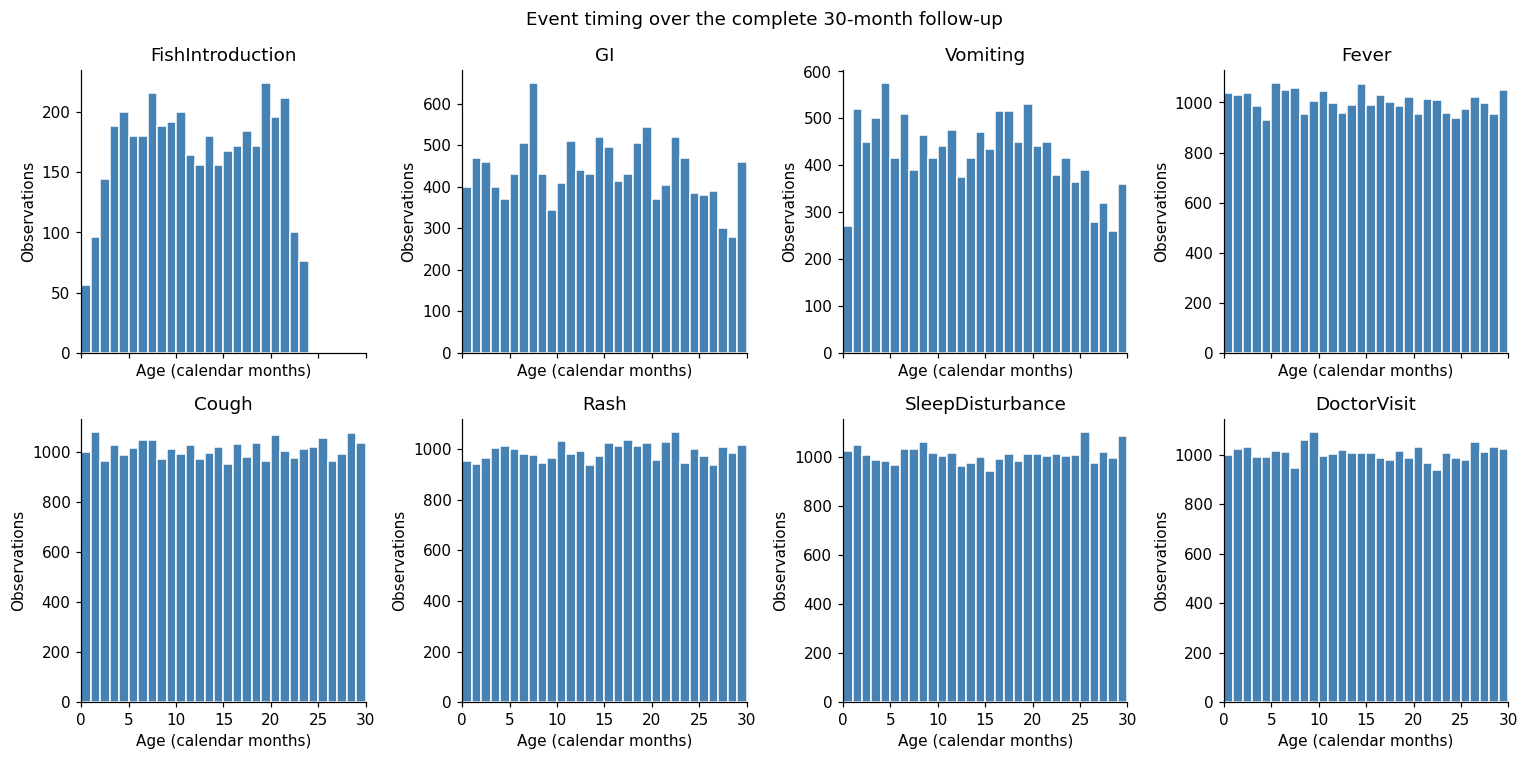

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True)
for ax, feature in zip(axes.flat, EVENT_FEATURES):
    ages = events.loc[events.feature_name.eq(feature), "age_months"]
    ax.hist(ages, bins=np.arange(0, 31), color="steelblue", edgecolor="white")
    ax.set(title=feature, xlabel="Age (calendar months)", ylabel="Observations", xlim=(0, 30))
fig.suptitle("Event timing over the complete 30-month follow-up")
fig.tight_layout()
plt.show()


## D. Ground-truth temporal relationship

R=1 only when a documented fish introduction is followed by **GI or vomiting** at
`fish_time < symptom_time <= fish_time + 1 calendar month`.
Undocumented introduction means R=0 under this synthetic rule.

The following calculation uses actual observation timestamps, not the intended
profile or the `signal_time` metadata. Background GI/vomiting events are included
in the calculation: their exclusion from qualifying windows must arise from their
actual timestamps. Distractor events never contribute to R, even inside a shaded
post-introduction window. FA is a noisy Bernoulli outcome, not a copy of R.


In [7]:
fish = observations.loc[observations.feature_name.eq(FISH), ["patient_id", "time"]].rename(
    columns={"time": "observed_fish_time"}
)
assert fish.patient_id.is_unique
fish["window_end"] = fish.observed_fish_time.map(lambda t: t + pd.DateOffset(months=1))
symptoms = observations.loc[
    observations.feature_name.isin(SYMPTOMS), ["patient_id", "feature_name", "time"]
].merge(fish, on="patient_id", how="inner", validate="many_to_one")
qualifies = (symptoms.time > symptoms.observed_fish_time) & (symptoms.time <= symptoms.window_end)
positive_ids = set(symptoms.loc[qualifies, "patient_id"])
recomputed_R = patients.patient_id.isin(positive_ids).astype(int)
assert recomputed_R.equals(patients.R)
assert patients.fa_probability.eq(np.where(recomputed_R.eq(1), .90, .05)).all()

block_counts = patients.assign(
    documented_R1=patients.documented & recomputed_R.eq(1),
    documented_R0=patients.documented & recomputed_R.eq(0),
    undocumented=~patients.documented,
).groupby("block")[["documented_R1", "documented_R0", "undocumented"]].sum()
assert block_counts.eq([4, 4, 2]).all().all()
print("All saved R values agree with the observed timestamps; every block is 4/4/2.")
display(patients.groupby("R").agg(children=("patient_id", "size"), FA_prevalence=("FA", "mean")))
display(patients.groupby(["documented", "R"]).agg(
    children=("patient_id", "size"), FA_cases=("FA", "sum"),
    observed_FA_prevalence=("FA", "mean"), expected_FA_probability=("fa_probability", "first"),
))


All saved R values agree with the observed timestamps; every block is 4/4/2.


,children,FA_prevalence
R,,
0,3000,0.044667
1,2000,0.903000


children  FA_cases  observed_FA_prevalence  \
documented R                                               
False      0      1000        40                   0.040   
True       0      2000        94                   0.047   
           1      2000      1806                   0.903   

              expected_FA_probability  
documented R                           
False      0                     0.05  
True       0                     0.05  
           1                     0.90

### Representative patient timelines

The first ordinary block supplies profiles 1 (qualifying), 5 (symptom too late),
7 (symptom before introduction), and 9 (undocumented). Selection does not depend
on FA. Change `example_block` or `example_profiles` to inspect other children;
use an endpoint or boundary block to inspect exact calendar-month boundaries.

Stars indicate qualifying GI/vomiting events. Orange points are GI/vomiting
outside the true window. Gray crosses are distractors, regardless of their dates.
All plotted times come from the observation table; no events are imputed.


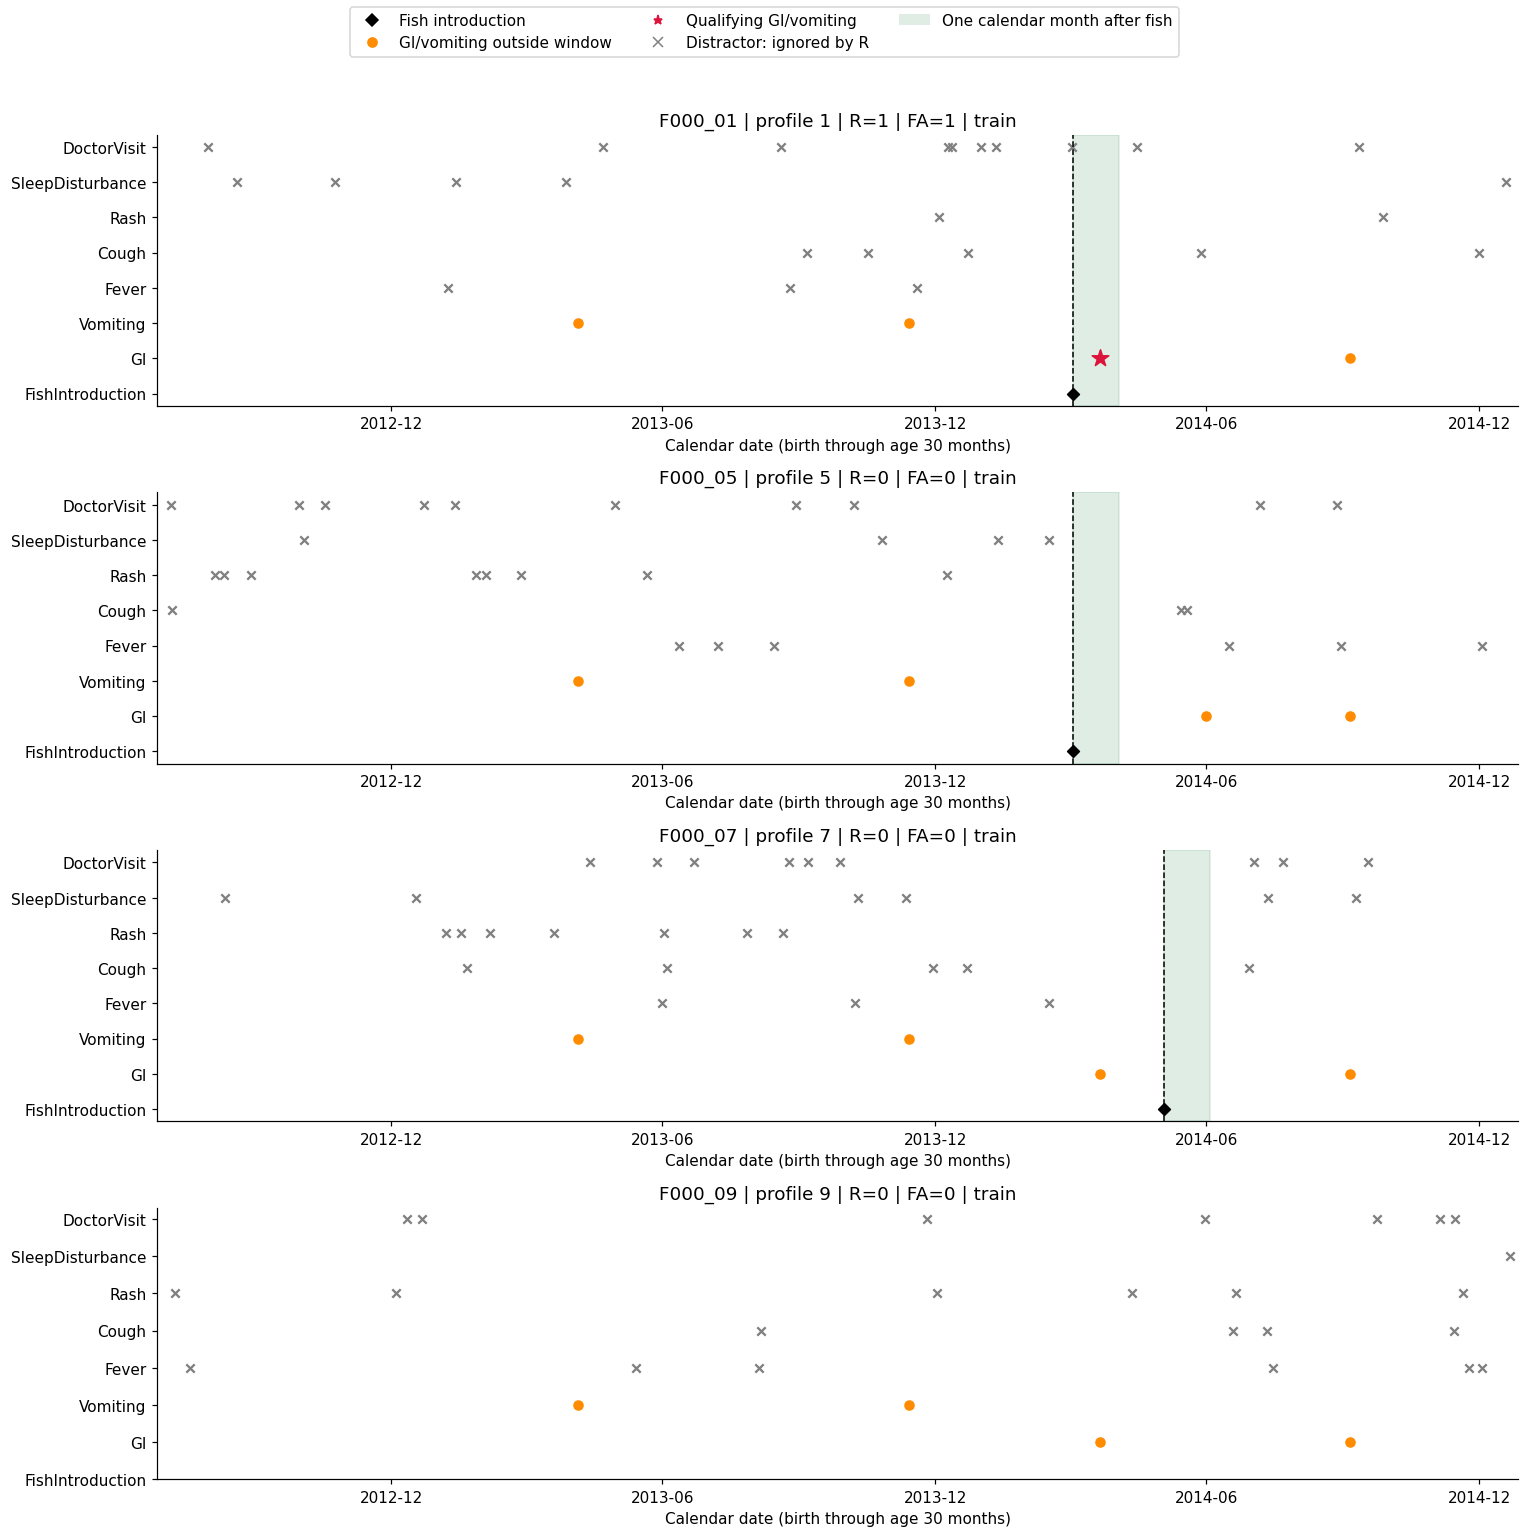

In [8]:
example_block = patients.loc[patients.scenario.eq("ordinary"), "block"].iloc[0]
example_profiles = [1, 5, 7, 9]
examples = patients.loc[
    patients.block.eq(example_block) & patients.profile.isin(example_profiles)
].sort_values("profile")
fig, axes = plt.subplots(len(examples), 1, figsize=(14, 3.5 * len(examples)), squeeze=False)
for ax, child in zip(axes.flat, examples.itertuples(index=False)):
    rows = observations.loc[observations.patient_id.eq(child.patient_id)]
    fish_times = rows.loc[rows.feature_name.eq(FISH), "time"]
    fish_time = fish_times.iloc[0] if len(fish_times) else None
    if fish_time is not None:
        window_end = fish_time + pd.DateOffset(months=1)
        ax.axvspan(fish_time, window_end, color="seagreen", alpha=.15)
        ax.axvline(fish_time, color="black", linestyle="--", linewidth=1)
    for y, feature in enumerate(EVENT_FEATURES):
        times = rows.loc[rows.feature_name.eq(feature), "time"]
        if feature in SYMPTOMS:
            qualifying = pd.Series(False, index=times.index)
            if fish_time is not None:
                qualifying = (times > fish_time) & (times <= window_end)
            ax.scatter(times.loc[~qualifying], np.full((~qualifying).sum(), y), color="darkorange", s=35)
            ax.scatter(times.loc[qualifying], np.full(qualifying.sum(), y), color="crimson", marker="*", s=130)
        else:
            ax.scatter(times, np.full(len(times), y),
                       color="black" if feature == FISH else "gray",
                       marker="D" if feature == FISH else "x", s=30)
    ax.set_yticks(range(len(EVENT_FEATURES)))
    ax.set_yticklabels(EVENT_FEATURES)
    ax.set_xlim(child.birth, child.followup_end)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.set_title(f"{child.patient_id} | profile {child.profile} | R={child.R} | FA={child.FA} | {child.partition}")
    ax.set_xlabel("Calendar date (birth through age 30 months)")
handles = [
    Line2D([], [], color="black", marker="D", linestyle="none", label="Fish introduction"),
    Line2D([], [], color="darkorange", marker="o", linestyle="none", label="GI/vomiting outside window"),
    Line2D([], [], color="crimson", marker="*", linestyle="none", label="Qualifying GI/vomiting"),
    Line2D([], [], color="gray", marker="x", linestyle="none", label="Distractor: ignored by R"),
    Patch(facecolor="seagreen", alpha=.15, label="One calendar month after fish"),
]
fig.legend(handles=handles, loc="upper center", ncol=3)
fig.tight_layout(rect=(0, 0, 1, .94))
plt.show()


## E. Distractor checks

Independent generation does not require exact empirical equality between groups.
Compare counts and presence using **all children, including zeros**. Differences
can occur by chance, and presence is near universal because counts follow
Poisson(6). Absence groups can consequently be very small.

These are descriptive associations, not clinical effects or reasons to select
features. Do not rebalance, delete events, or modify the generator based on them.
Tables include held-out children and must not be used to tune the predictive models.


children  mean_count  count_std  presence_rate
feature_name     R                                                
Cough            0      3000    6.065667   2.462934       0.997000
                 1      2000    6.056000   2.513369       0.997500
DoctorVisit      0      3000    5.999667   2.510199       0.999000
                 1      2000    6.082500   2.472398       0.999000
Fever            0      3000    6.041000   2.404284       0.998333
                 1      2000    6.002000   2.429392       0.999500
Rash             0      3000    5.906667   2.466979       0.996667
                 1      2000    5.982500   2.387895       0.998000
SleepDisturbance 0      3000    6.026333   2.480663       0.997667
                 1      2000    6.119500   2.526739       0.997000

Documented-introduction children only:


children  mean_count  presence_rate
feature_name     R                                     
Cough            0      2000      6.0490         0.9985
                 1      2000      6.0560         0.9975
DoctorVisit      0      2000      5.9440         0.9995
                 1      2000      6.0825         0.9990
Fever            0      2000      6.0485         0.9990
                 1      2000      6.0020         0.9995
Rash             0      2000      5.9415         0.9975
                 1      2000      5.9825         0.9980
SleepDisturbance 0      2000      6.0370         0.9980
                 1      2000      6.1195         0.9970

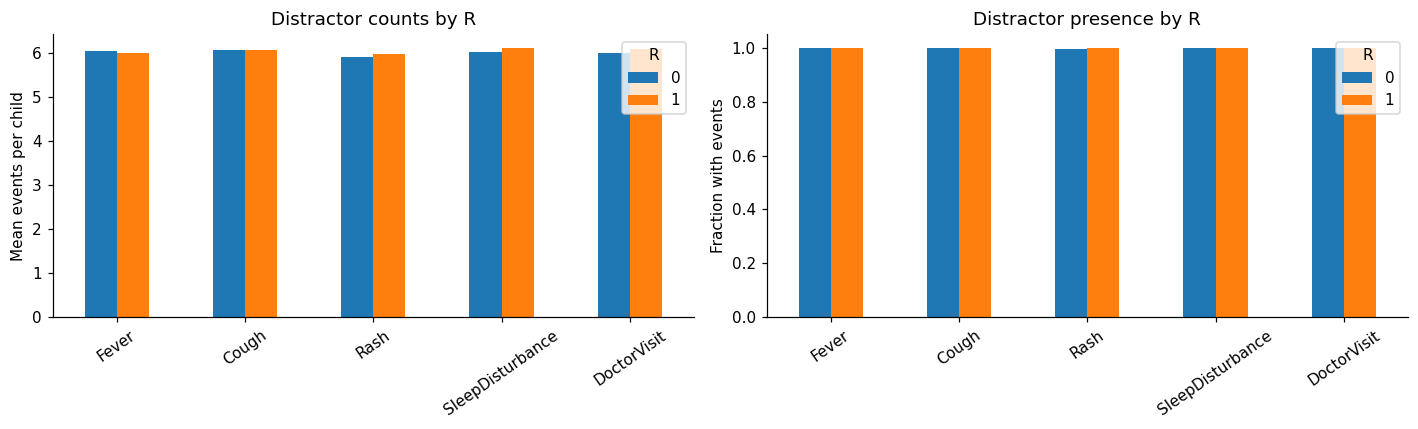

In [9]:
distractor_long = (
    counts[DISTRACTORS].reset_index()
    .melt(id_vars="patient_id", var_name="feature_name", value_name="count")
    .merge(patients[["patient_id", "R", "FA", "documented", "partition"]],
           on="patient_id", validate="many_to_one")
)
distractor_long["present"] = distractor_long["count"].gt(0)
by_R = distractor_long.groupby(["feature_name", "R"]).agg(
    children=("patient_id", "size"), mean_count=("count", "mean"),
    count_std=("count", "std"), presence_rate=("present", "mean"),
)
display(by_R)
print("Documented-introduction children only:")
display(distractor_long.loc[distractor_long.documented].groupby(["feature_name", "R"]).agg(
    children=("patient_id", "size"), mean_count=("count", "mean"),
    presence_rate=("present", "mean"),
))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_R.mean_count.unstack("R").reindex(DISTRACTORS).plot.bar(ax=axes[0])
by_R.presence_rate.unstack("R").reindex(DISTRACTORS).plot.bar(ax=axes[1])
axes[0].set(title="Distractor counts by R", ylabel="Mean events per child", xlabel="")
axes[1].set(title="Distractor presence by R", ylabel="Fraction with events", xlabel="", ylim=(0, 1.05))
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()


In [10]:
associations = []
for feature in DISTRACTORS:
    for population in ["all children", "documented only"]:
        group = distractor_long.loc[distractor_long.feature_name.eq(feature)]
        if population == "documented only":
            group = group.loc[group.documented]
        associations.append({
            "feature": feature, "population": population, "children": len(group),
            "count_FA_correlation": group["count"].corr(group.FA),
            "presence_FA_correlation": group.present.astype(int).corr(group.FA),
        })
display(pd.DataFrame(associations))
display(distractor_long.groupby(["feature_name", "present"]).agg(
    children=("patient_id", "size"), FA_cases=("FA", "sum"), FA_prevalence=("FA", "mean"),
))


,feature,population,children,count_FA_correlation,presence_FA_correlation
0,Fever,all children,5000,-0.010928,0.015744
1,Fever,documented only,4000,-0.013911,0.007772
2,Cough,all children,5000,0.001506,0.011123
3,Cough,documented only,4000,0.007889,-0.002241
4,Rash,all children,5000,0.011834,0.011123
5,Rash,documented only,4000,0.005456,0.002906
6,SleepDisturbance,all children,5000,0.009462,0.000355
7,SleepDisturbance,documented only,4000,0.005052,-0.002506
8,DoctorVisit,all children,5000,0.005489,0.025192
9,DoctorVisit,documented only,4000,0.014562,0.026059


children  FA_cases  FA_prevalence
feature_name     present                                   
Cough            False          14         4       0.285714
                 True         4986      1936       0.388287
DoctorVisit      False           5         0       0.000000
                 True         4995      1940       0.388388
Fever            False           6         1       0.166667
                 True         4994      1939       0.388266
Rash             False          14         4       0.285714
                 True         4986      1936       0.388287
SleepDisturbance False          13         5       0.384615
                 True         4987      1935       0.388009

Correlations are descriptive Pearson correlations; for binary FA, the count
correlation is also called point-biserial correlation. Undefined correlations
appear as NaN if a variable has no variation. No thresholds, significance tests,
feature exclusions, or data changes are applied here.

Plots remain in the notebook when you execute it. This notebook does not save
figures automatically, and its inspection variables are never supplied to a model.
